<a href="https://colab.research.google.com/github/andresjaimes2004/tesis-desercion/blob/main/notebooks/02_preparacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · Preparación de los datos

Fase 3 de CRISP-DM. Verifica la consistencia de los registros, separa el conjunto de prueba, define las variables de cada momento y deja listo el preprocesamiento que usarán los modelos de la Fase 4. Al final regenera las figuras de la Fase 2 con etiquetas en español.

In [1]:
# Preparar el entorno (igual que en el cuaderno 00)
import os, sys
REPO_URL = "https://github.com/andresjaimes2004/tesis-desercion.git"
REPO_DIR = "/content/tesis-desercion"
if "google.colab" in sys.modules and not os.path.exists(REPO_DIR):
    !git clone -q {REPO_URL} {REPO_DIR}
if os.path.exists(REPO_DIR):
    os.chdir(REPO_DIR)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
%pip install -q -r requirements.txt

In [2]:
import pandas as pd
from src import config, eda, plots, prep
from src.data import load_raw, binarize_target, features_for_moment
from src.utils import set_seed

set_seed()
pd.set_option("display.max_columns", 50)
config.REPORTS.mkdir(parents=True, exist_ok=True)

base = binarize_target(load_raw())           # conjunto tal como se analizó en la Fase 2
df = prep.add_no_enrollment_flags(base)      # agrega los indicadores de semestre sin inscripción
print(base.shape, "->", df.shape)

(4424, 38) -> (4424, 40)


## 1. Verificación de consistencia

Se revisan reglas lógicas entre variables. La celda solo cuenta incumplimientos; no elimina registros.

In [3]:
consistencia = prep.consistency_checks(base)
consistencia.to_csv(config.REPORTS / "verificacion_consistencia.csv", index=False, encoding="utf-8-sig")
consistencia

,semestre,regla,incumplimientos
0,1.er semestre,Unidades aprobadas mayores que las inscritas,0
1,1.er semestre,Nota promedio fuera de la escala 0 a 20,0
2,1.er semestre,Nota promedio mayor que cero sin unidades apro...,0
3,1.er semestre,Unidades aprobadas sin nota promedio,0
4,2.º semestre,Unidades aprobadas mayores que las inscritas,0
5,2.º semestre,Nota promedio fuera de la escala 0 a 20,0
6,2.º semestre,Nota promedio mayor que cero sin unidades apro...,0
7,2.º semestre,Unidades aprobadas sin nota promedio,0
8,matrícula,"Edad al ingresar fuera de [15, 80]",0
9,matrícula,"Puntaje de admisión fuera de [0, 200]",0


Estudiantes sin unidades inscritas en ninguno de los dos semestres. En ellos la nota y las unidades aprobadas valen 0 aunque no cursaron nada, por eso se agrega un indicador que distingue ese caso de un semestre perdido.

In [4]:
sin_inscripcion = prep.no_enrollment_by_course(base)
sin_inscripcion.to_csv(config.REPORTS / "sin_inscripcion_por_programa.csv", encoding="utf-8-sig")
sin_inscripcion

Target,Dropout,Enrolled,Graduate,total_sin_inscripcion,estudiantes_programa,pct_del_programa
Course,,,,,,
171,77,28,75,180,215,83.7


## 2. Partición entrenamiento / prueba

Partición estratificada 80/20 con semilla 42. El conjunto de prueba queda guardado en `reports/particion.csv` y no se vuelve a tocar hasta la evaluación final (Fase 5).

In [5]:
idx_train, idx_test = prep.split(df)
prep.save_split(idx_train, idx_test)
resumen_particion = prep.split_summary(df, idx_train, idx_test)
resumen_particion.to_csv(config.REPORTS / "particion_resumen.csv", index=False, encoding="utf-8-sig")
resumen_particion

,conjunto,registros,desercion,pct_desercion
0,entrenamiento,3539,1137,32.1
1,prueba,885,284,32.1
2,total,4424,1421,32.1


## 3. Variables por momento y preprocesamiento

- Categóricas: codificación one-hot. Las categorías con menos de 30 registros **en el entrenamiento** se agrupan en una sola columna.
- Binarias: se mantienen como 0/1.
- Numéricas: estandarización (media 0, desviación 1), necesaria para la regresión logística.

El preprocesamiento se ajusta solo con datos de entrenamiento. Se compara el conjunto completo con el conjunto sin las variables no significativas de la Fase 2; la decisión entre ambos se toma en la Fase 4 con validación cruzada.

In [6]:
no_signif = prep.non_significant()
print("No significativas en la Fase 2:", no_signif)

prep_completo = prep.preprocessing_summary(df, idx_train).assign(conjunto="completo")
prep_reducido = prep.preprocessing_summary(df, idx_train, exclude=no_signif).assign(conjunto="sin no significativas")
resumen_prep = pd.concat([prep_completo, prep_reducido], ignore_index=True)
resumen_prep.to_csv(config.REPORTS / "preparacion_resumen.csv", index=False, encoding="utf-8-sig")
resumen_prep

No significativas en la Fase 2: ['Inflation rate', 'Nacionality', 'Curricular units 2nd sem (credited)', 'Unemployment rate', 'International', 'Curricular units 1st sem (credited)', 'Educational special needs']


,momento,variables,categoricas,binarias,numericas,categorias_agrupadas,columnas_tras_codificar,conjunto
0,matricula,24,9,8,7,132,100,completo
1,semestre_1,31,9,9,13,132,107,completo
2,semestre_2,38,9,10,19,132,114,completo
3,matricula,19,8,6,5,114,94,sin no significativas
4,semestre_1,25,8,7,10,114,100,sin no significativas
5,semestre_2,31,8,8,15,114,106,sin no significativas


## 4. Balanceo de clases (ilustración)

SMOTE-NC genera casos sintéticos de deserción tratando las variables categóricas como tales. En la Fase 4 se aplica **dentro de cada pliegue** de la validación cruzada; aquí solo se muestra su efecto sobre el entrenamiento del momento semestre 2.

In [7]:
balanceo = prep.smote_demo(df, idx_train)
balanceo.to_csv(config.REPORTS / "balanceo_smote_nc.csv", encoding="utf-8-sig")
balanceo

,antes,despues
deserta,,
no deserta,2402,2402
deserta,1137,2402


## 5. Prueba rápida del pipeline

Comprueba que el pipeline completo (SMOTE-NC, preprocesamiento y un modelo) entrena sin errores en los tres momentos. No es todavía la evaluación de modelos.

In [8]:
import warnings
warnings.filterwarnings("ignore", message="Unknown solver options")  # aviso interno de SciPy, no afecta el resultado
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=config.SEED)
train = df.loc[idx_train]
for m in config.MOMENTS:
    cols = features_for_moment(df, m)
    pipe = prep.build_pipeline(df, cols, LogisticRegression(max_iter=2000))
    rec = cross_val_score(pipe, train[cols], train[config.BINARY_TARGET], cv=cv, scoring="recall")
    print(f"{m:11s} variables={len(cols):2d}  sensibilidad CV={rec.mean():.3f} ± {rec.std():.3f}")

matricula   variables=24  sensibilidad CV=0.670 ± 0.006
semestre_1  variables=31  sensibilidad CV=0.775 ± 0.016
semestre_2  variables=38  sensibilidad CV=0.796 ± 0.022


## 6. Figuras de la Fase 2 en español

Se regeneran con los mismos datos y cálculos; solo cambian las etiquetas.

Figuras actualizadas en /content/tesis-desercion/reports/figures


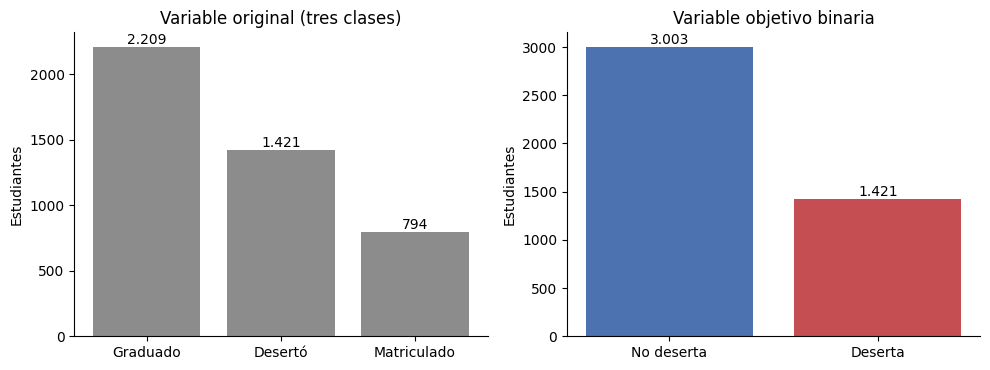

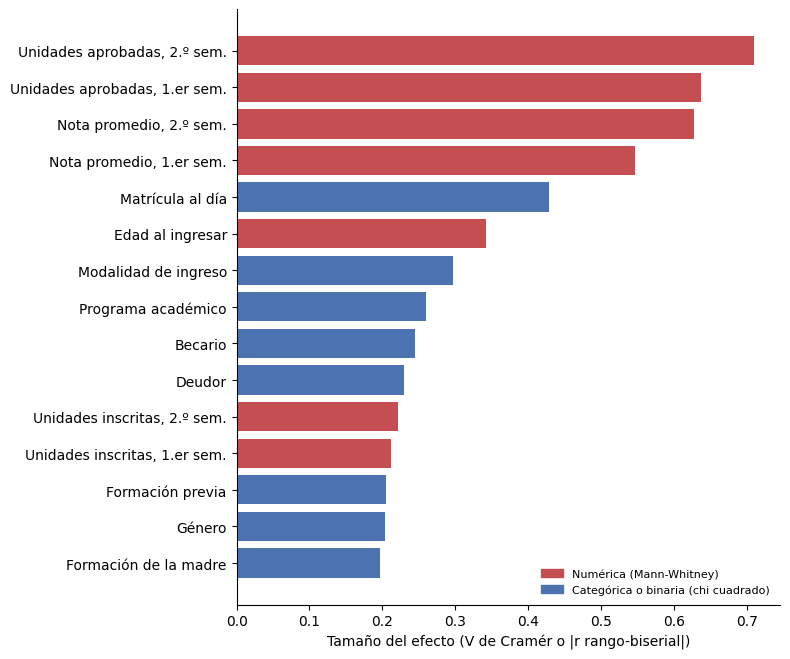

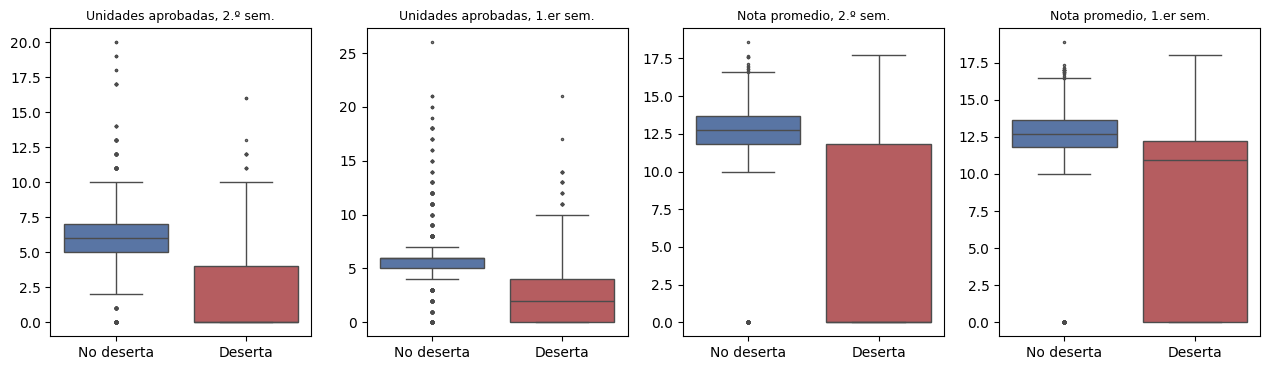

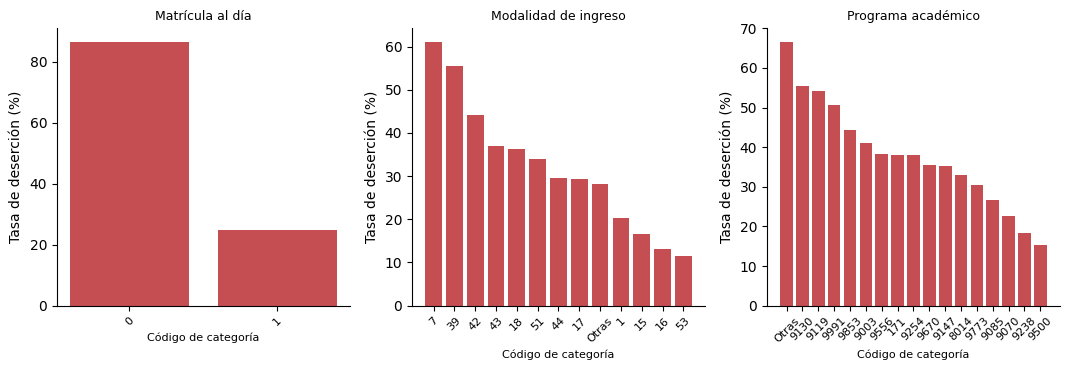

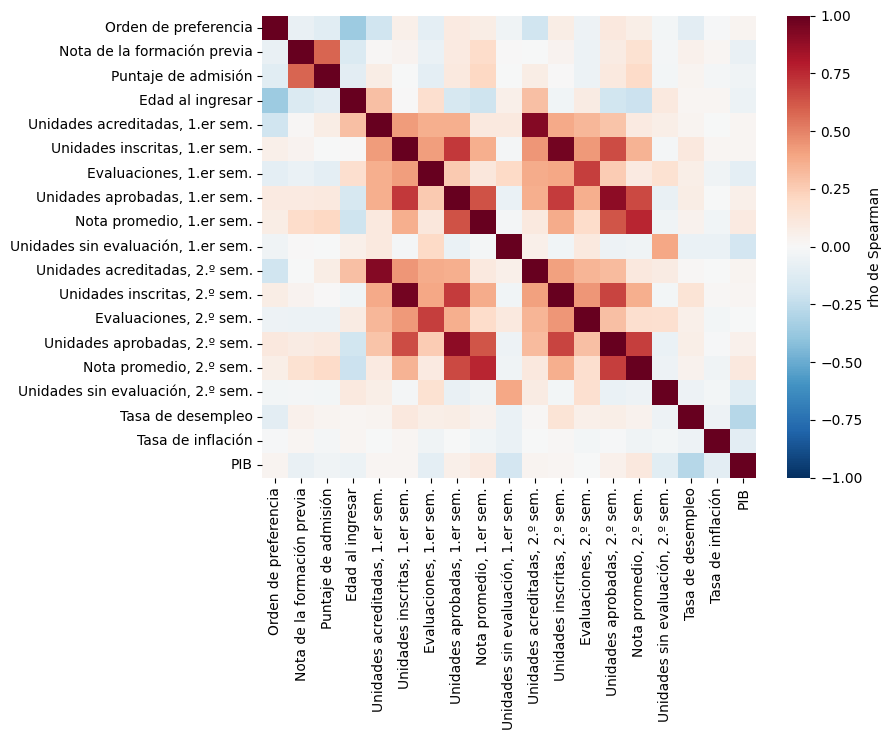

In [9]:
asoc = eda.association_table(base)
tipos = {c: eda.variable_type(base, c) for c in eda.predictors(base)}
numericas = [c for c, t in tipos.items() if t == "numérica"]
top_num = asoc.query("tipo == 'numérica'")["variable"].head(4).tolist()
top_cat = asoc.query("tipo != 'numérica'")["variable"].head(3).tolist()

plots.target_distribution(base)
plots.effect_sizes(asoc)
plots.numeric_by_group(base, top_num)
plots.categorical_rates({c: eda.dropout_rate_by_category(base, c) for c in top_cat})
plots.spearman_heatmap(base, numericas)
print("Figuras actualizadas en", config.FIGURES)

## 7. Resumen para el documento

Ejecutar esta celda y enviar su salida completa.

In [10]:
print("CONSISTENCIA (incumplimientos):")
print(consistencia.to_string(index=False))
print("\nSIN UNIDADES INSCRITAS EN AMBOS SEMESTRES:", int(sin_inscripcion["total_sin_inscripcion"].sum()))
print(sin_inscripcion.to_string())
print("\nPARTICIÓN:")
print(resumen_particion.to_string(index=False))
print("\nPREPROCESAMIENTO POR MOMENTO:")
print(resumen_prep.to_string(index=False))
print("\nBALANCEO SMOTE-NC (entrenamiento, semestre 2):")
print(balanceo.to_string())

CONSISTENCIA (incumplimientos):
     semestre                                               regla  incumplimientos
1.er semestre        Unidades aprobadas mayores que las inscritas                0
1.er semestre             Nota promedio fuera de la escala 0 a 20                0
1.er semestre Nota promedio mayor que cero sin unidades aprobadas                0
1.er semestre                Unidades aprobadas sin nota promedio                0
 2.º semestre        Unidades aprobadas mayores que las inscritas                0
 2.º semestre             Nota promedio fuera de la escala 0 a 20                0
 2.º semestre Nota promedio mayor que cero sin unidades aprobadas                0
 2.º semestre                Unidades aprobadas sin nota promedio                0
    matrícula                  Edad al ingresar fuera de [15, 80]                0
    matrícula               Puntaje de admisión fuera de [0, 200]                0
    matrícula       Nota de la formación previa fuera d

## 8. Guardar resultados en GitHub

Descargar la carpeta `reports/` (CSV y figuras) desde el panel de archivos y subirla al repositorio con el mensaje `Fase 3: preparación de los datos`. Guardar también este cuaderno con Archivo > Guardar una copia en GitHub.

In [11]:
!cd /content/tesis-desercion && zip -r /content/reports_fase3.zip reports

  adding: reports/ (stored 0%)
  adding: reports/diccionario_variables.csv (deflated 74%)
  adding: reports/preparacion_resumen.csv (deflated 48%)
  adding: reports/pares_redundantes.csv (deflated 53%)
  adding: reports/balanceo_smote_nc.csv (deflated 30%)
  adding: reports/particion.csv (deflated 85%)
  adding: reports/figures/ (stored 0%)
  adding: reports/figures/fig_03_numericas_por_grupo.png (deflated 26%)
  adding: reports/figures/fig_04_tasa_por_categoria.png (deflated 20%)
  adding: reports/figures/fig_02_tamano_efecto.png (deflated 22%)
  adding: reports/figures/fig_05_correlacion_spearman.png (deflated 17%)
  adding: reports/figures/fig_01_distribucion_objetivo.png (deflated 24%)
  adding: reports/asociacion_variables.csv (deflated 66%)
  adding: reports/verificacion_consistencia.csv (deflated 65%)
  adding: reports/entorno.json (deflated 46%)
  adding: reports/descriptivos_numericas.csv (deflated 76%)
  adding: reports/particion_resumen.csv (deflated 16%)
  adding: reports/s